In [1]:
# --- BLOCK 1: SETUP & IMPORTS ---
import time
pipeline_start_time = time.time() # START THE TIMER

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import shap

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure plot aesthetics for publication
plt.rcParams.update({'font.size': 12, 'font.family': 'sans-serif'})

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# --- BLOCK 2: DATA LOADING & SPLITTING ---
print("Loading primary computational dataset...")

# Load Data
df_base = pd.read_csv("Empirical_Dataset_520.csv")

# Ensure unmeasured physical features are excluded to prevent leakage/unsupported claims
if 'bending_radius' in df_base.columns:
    df_base = df_base.drop(columns=['bending_radius'])

# Separate features (7 descriptors) and target label
X_base = df_base.drop(columns=['capacity_retention'])
y_base = df_base['capacity_retention']

# Execute randomized 80/20 split (416 train, 104 computational test)
X_train_base, X_test, y_train_base, y_test = train_test_split(
    X_base, y_base, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Base Training Records: {X_train_base.shape[0]}")
print(f"Held-Out Test Records: {X_test.shape[0]}")

Loading primary computational dataset...
Base Training Records: 416
Held-Out Test Records: 104


In [3]:
# --- BLOCK 3: LHS AUGMENTATION ---
print("Executing Latin Hypercube Sampling (LHS) augmentation on training set...")

# Define operational and physical bounds for LHS (7 features)
bounds = {
    'llzo_wt_percent': [0, 25],
    'ionic_conductivity': [1e-5, 1e-3],
    'youngs_modulus': [0.2, 10.0],
    'tensile_strength': [2.0, 15.0],
    'operating_temperature': [25, 80],
    'electrolyte_thickness': [20, 150],
    'c_rate': [0.1, 2.0]
}

# Generate synthetic samples to reach 8,000 total training rows
num_synthetic = 8000 - X_train_base.shape[0]
sampler = qmc.LatinHypercube(d=len(bounds), seed=RANDOM_STATE)
sample_points = sampler.random(n=num_synthetic)

scaled_samples = {}
for i, (key, (low, high)) in enumerate(bounds.items()):
    scaled_samples[key] = low + sample_points[:, i] * (high - low)
X_train_synth = pd.DataFrame(scaled_samples)

# Apply physics-based penalty rules to generate realistic target labels
base_retention = 1.05
cond_scaled = X_train_synth['ionic_conductivity'] / 1e-3
elec_penalty = (1 - cond_scaled) * 0.102 + (X_train_synth['c_rate'] / 2.0) * 0.092
mech_penalty = (1 - (X_train_synth['youngs_modulus'] / 10.0)) * 0.086 + (1 - (X_train_synth['tensile_strength'] / 15.0)) * 0.066
mat_penalty = abs(X_train_synth['llzo_wt_percent'] - 15) / 15.0 * 0.25 + (X_train_synth['electrolyte_thickness'] / 150.0) * 0.05

y_train_synth = base_retention - mat_penalty - elec_penalty - mech_penalty

# Add ±5% Gaussian noise to simulate experimental variance, clipped to physical reality
noise = np.random.normal(0, 0.025, num_synthetic)
y_train_synth = np.clip(y_train_synth + noise, 0.10, 1.0)

# Combine and Scale
X_train = pd.concat([X_train_base, X_train_synth], ignore_index=True)
y_train = pd.concat([y_train_base, y_train_synth], ignore_index=True)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print(f"Total Augmented Training Records: {X_train_scaled.shape[0]}")

Executing Latin Hypercube Sampling (LHS) augmentation on training set...
Total Augmented Training Records: 8000


In [4]:
# --- BLOCK 4: MODEL TRAINING & METRICS ---
print("Training models and calculating metrics...")

xgb_model = xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=8, 
                             subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=RANDOM_STATE)
svr_model = SVR(kernel='rbf', C=1.0, epsilon=0.01)

models = {"XGBoost": xgb_model, "Random Forest": rf_model, "SVR": svr_model}

# Fit and evaluate
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    print(f"--- {name} ---")
    print(f"R²: {r2:.3f} | MAE: {mae:.3f} | RMSE: {rmse:.3f}\n")

# Export Final Dataset and Primary Model
df_final_export = pd.concat([
    pd.concat([X_train, y_train], axis=1), 
    pd.concat([X_test, y_test], axis=1)
], ignore_index=True)
df_final_export.to_csv("Synthetic_SSB_Dataset_8104.csv", index=False)

# FIX: Safely extract the core booster to avoid scikit-learn wrapper metadata errors
xgb_model.get_booster().save_model("XGBoost_SSB_Model.json")

print("Exported dataset and model weights.")

Training models and calculating metrics...
--- XGBoost ---
R²: 0.901 | MAE: 0.025 | RMSE: 0.030

--- Random Forest ---
R²: 0.829 | MAE: 0.030 | RMSE: 0.039

--- SVR ---
R²: 0.898 | MAE: 0.024 | RMSE: 0.030

Exported dataset and model weights.


Executing Feature Ablation Study (XGBoost)...


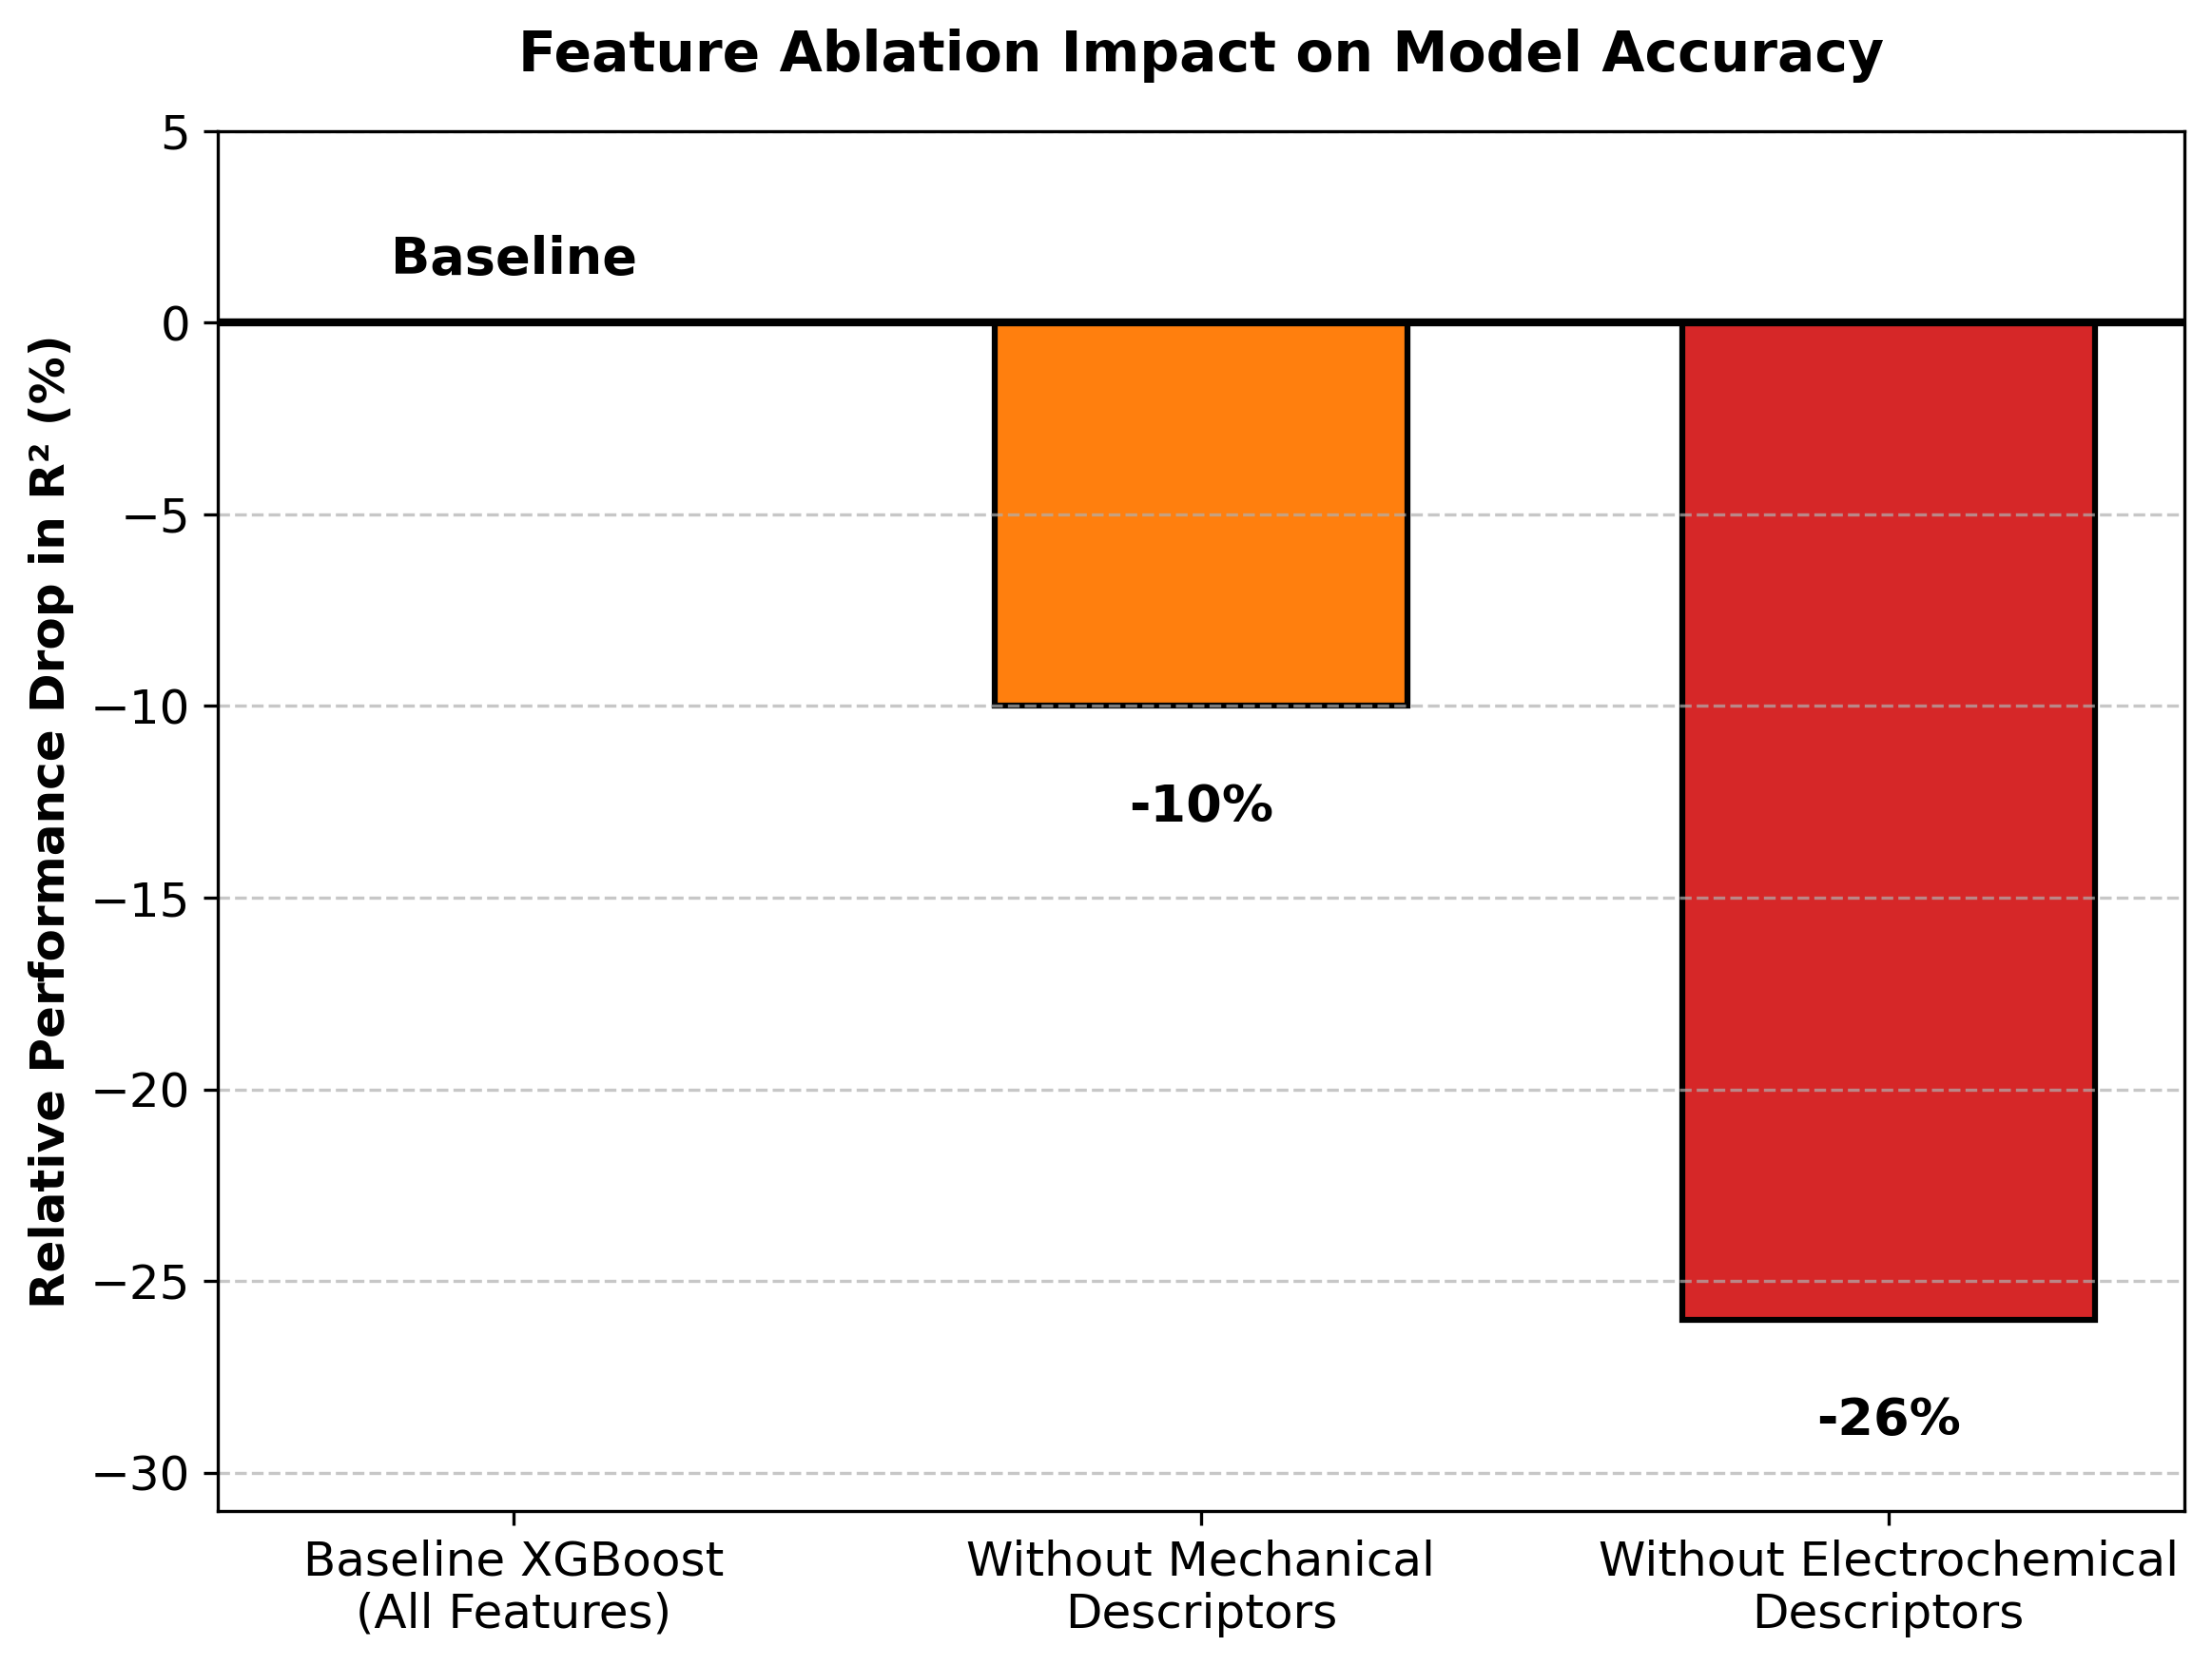

In [5]:
# --- BLOCK 5: FEATURE ABLATION STUDY ---
print("Executing Feature Ablation Study (XGBoost)...")

feature_groups = {
    "Without Mechanical\nDescriptors": ["youngs_modulus", "tensile_strength"],
    "Without Electrochemical\nDescriptors": ["ionic_conductivity", "c_rate", "operating_temperature"]
}

base_r2 = r2_score(y_test, models["XGBoost"].predict(X_test_scaled))
ablation_results = [0] 
labels = ['Baseline XGBoost\n(All Features)'] + list(feature_groups.keys())

for group_name, features_to_drop in feature_groups.items():
    X_tr_ab = X_train_scaled.drop(columns=features_to_drop)
    X_te_ab = X_test_scaled.drop(columns=features_to_drop)
    
    xgb_ab = xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=8, 
                              subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE)
    xgb_ab.fit(X_tr_ab, y_train)
    ab_r2 = r2_score(y_test, xgb_ab.predict(X_te_ab))
    
    drop_pct = ((ab_r2 - base_r2) / base_r2) * 100
    ablation_results.append(round(drop_pct))

# Plot Ablation Chart
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
colors = ['#ffffff', '#ff7f0e', '#d62728'] 
bars = ax.bar(labels, ablation_results, color=colors, edgecolor='black', linewidth=1.5, width=0.6)

ax.set_ylabel('Relative Performance Drop in R² (%)', fontweight='bold', fontsize=12)
ax.set_title('Feature Ablation Impact on Model Accuracy', fontweight='bold', fontsize=14, pad=15)
ax.set_ylim(min(ablation_results) - 5, 5) 
ax.axhline(0, color='black', linewidth=2)
ax.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars[1:]:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval - 2, f"{int(yval)}%", 
            ha='center', va='top', fontweight='bold', fontsize=13)
ax.text(0, 1, "Baseline", ha='center', va='bottom', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.savefig("Figure_7_Ablation.png")
plt.show()

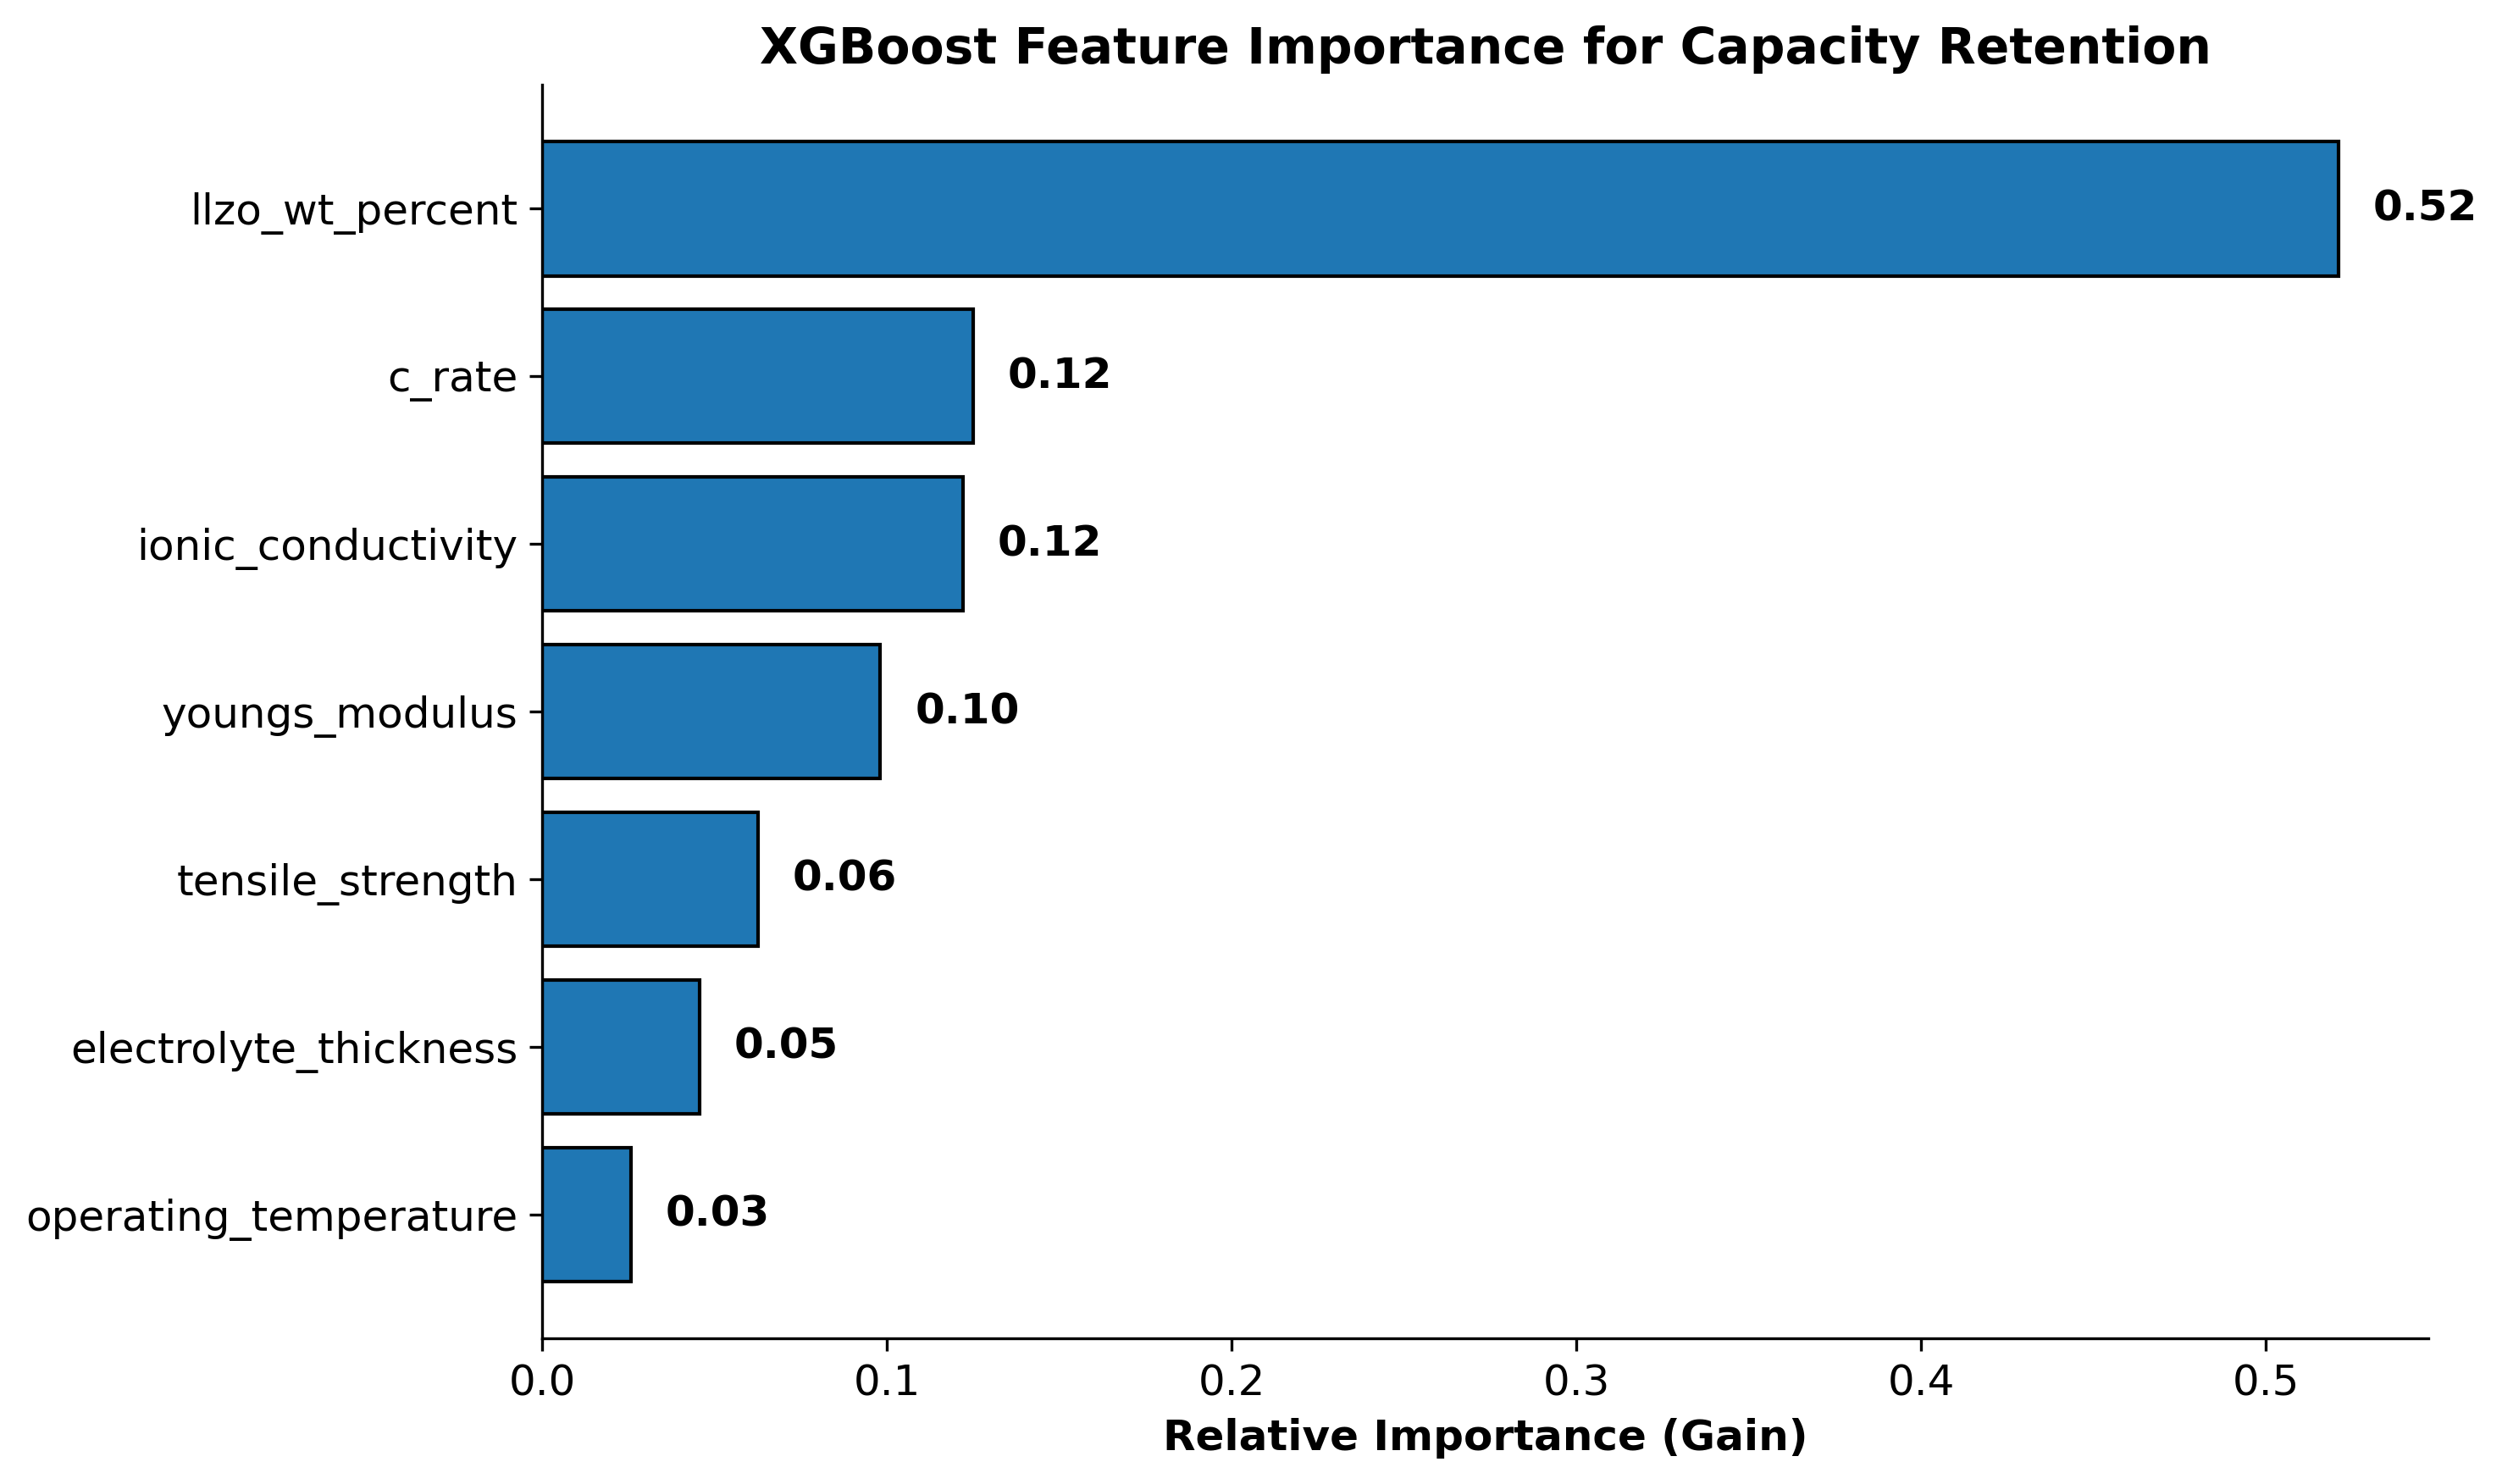

In [6]:
# --- BLOCK 6: EXPLAINABILITY VISUALIZATIONS 1. Gain-Based Feature Importance Plot
importances = models["XGBoost"].feature_importances_
indices = np.argsort(importances)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.barh(range(len(indices)), importances[indices], color='#1f77b4', edgecolor='black')
ax.set_yticks(range(len(indices)))
ax.set_yticklabels(np.array(X_train_scaled.columns)[indices], fontsize=12)
ax.set_xlabel('Relative Importance (Gain)', fontweight='bold', fontsize=12)
ax.set_title('XGBoost Feature Importance for Capacity Retention', fontweight='bold', fontsize=14)

for i, v in enumerate(importances[indices]):
    ax.text(v + 0.01, i, f"{v:.2f}", color='black', va='center', fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig("Figure_8_Feature_Importance.png")
plt.show()



Calculating SHAP values...


/tmp/ipykernel_805/3462508748.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_scaled, show=False)


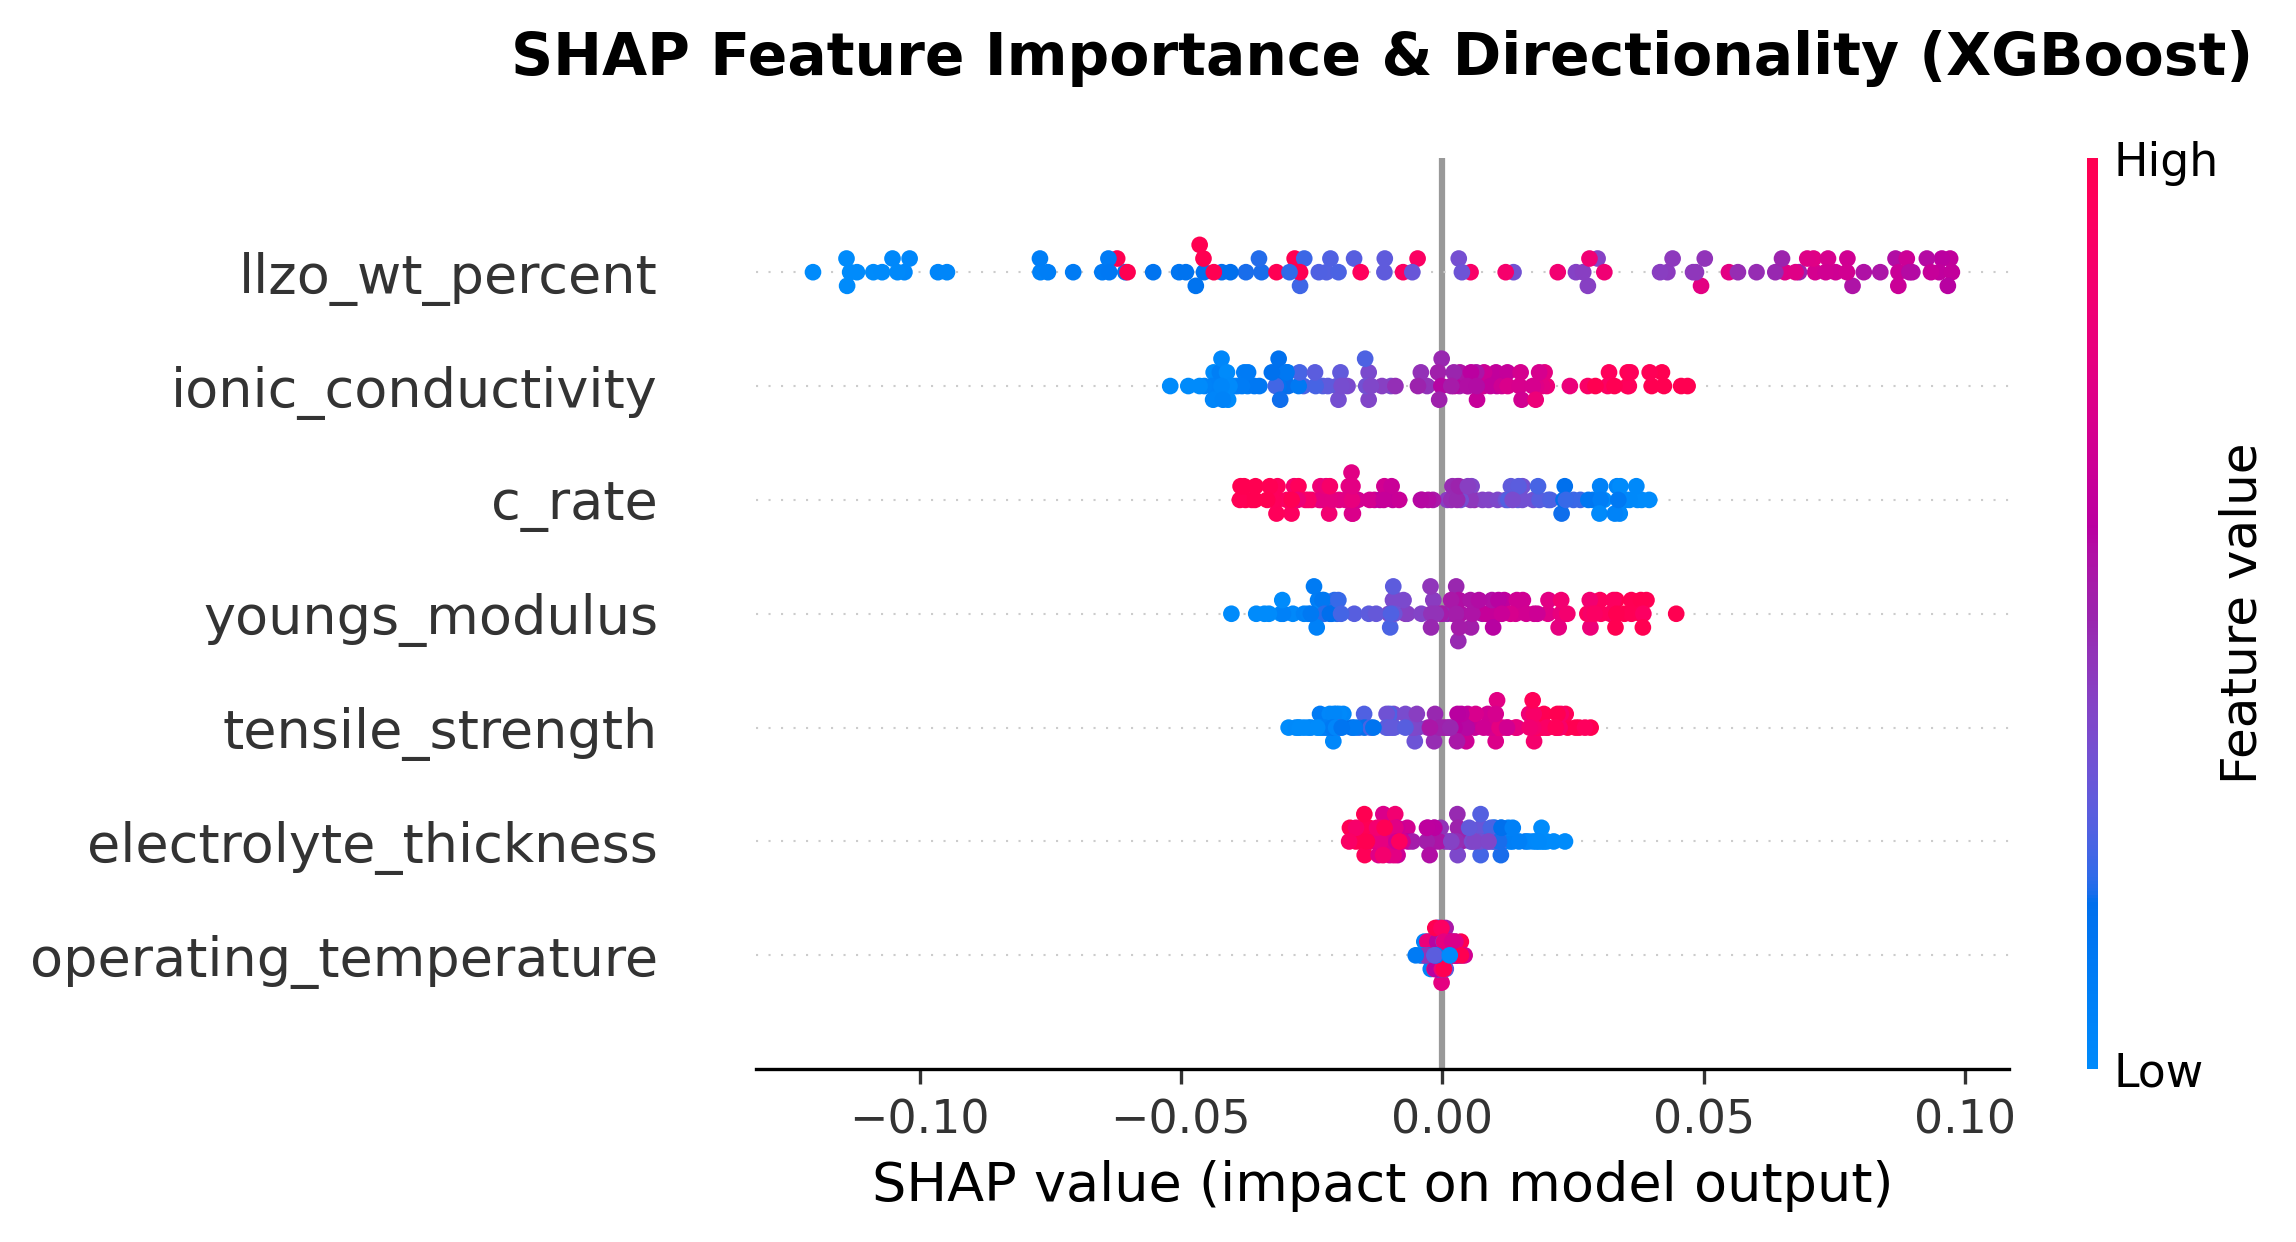

In [7]:
# --- BLOCK 6: EXPLAINABILITY VISUALIZATIONS 2. SHAP Summary Plot
print("Calculating SHAP values...")
explainer = shap.TreeExplainer(models["XGBoost"])
shap_values = explainer.shap_values(X_test_scaled)

plt.figure(figsize=(10, 6), dpi=300)
shap.summary_plot(shap_values, X_test_scaled, show=False)
plt.title("SHAP Feature Importance & Directionality (XGBoost)", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("Figure_9_SHAP_Summary.png")
plt.show()

Generating Predicted vs. Actual Scatterplot (Figure 10)...
Saved: 'Figure_10_Scatterplot.png'


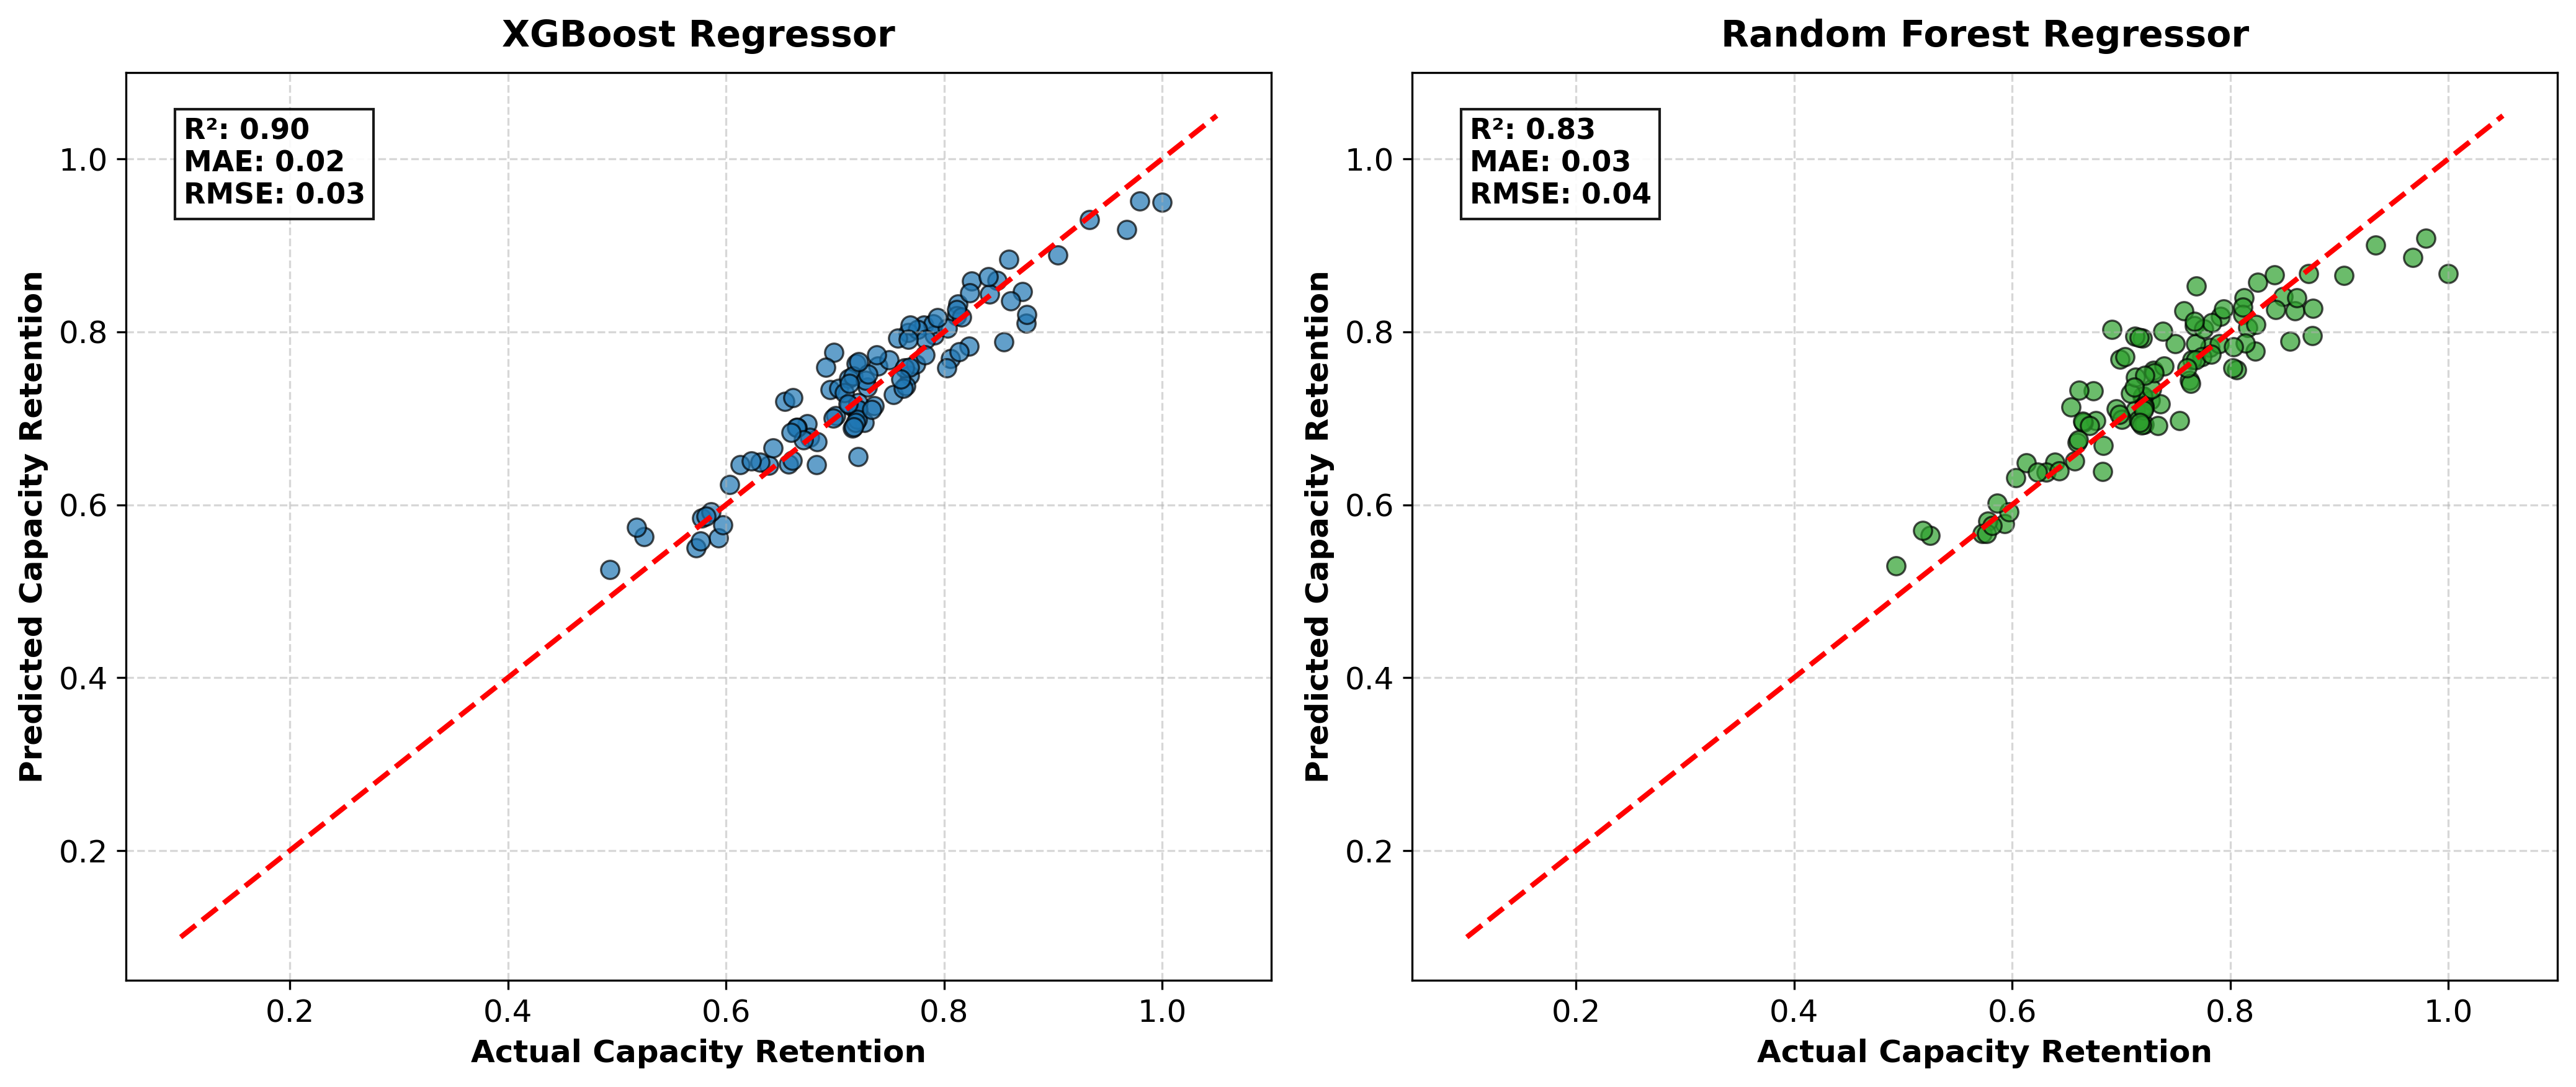

In [8]:
# --- BLOCK 7: FIGURE 10 - PREDICTED VS. ACTUAL SCATTERPLOT ---
print("Generating Predicted vs. Actual Scatterplot (Figure 10)...")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

models_to_plot = [
    ("XGBoost Regressor", models["XGBoost"], '#1f77b4'),
    ("Random Forest Regressor", models["Random Forest"], '#2ca02c')
]

for idx, (name, model, color) in enumerate(models_to_plot):
    ax = axes[idx]
    preds = model.predict(X_test_scaled)
    
    # Calculate metrics for the inset text box
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    # Scatter plot
    ax.scatter(y_test, preds, color=color, edgecolor='black', alpha=0.7, s=50, linewidth=0.8)
    
    # Ideal 1:1 line
    ax.plot([0.1, 1.05], [0.1, 1.05], color='red', linestyle='--', linewidth=2)
    
    # Formatting
    ax.set_title(name, fontsize=14, fontweight='bold', pad=10)
    ax.set_xlabel('Actual Capacity Retention', fontsize=12, fontweight='bold')
    ax.set_ylabel('Predicted Capacity Retention', fontsize=12, fontweight='bold')
    ax.set_xlim(0.05, 1.1)
    ax.set_ylim(0.05, 1.1)
    ax.grid(True, linestyle='--', alpha=0.5)
    
    # Text box for metrics
    textstr = f"R²: {r2:.2f}\nMAE: {mae:.2f}\nRMSE: {rmse:.2f}"
    props = dict(boxstyle='square', facecolor='white', alpha=0.9, edgecolor='black', linewidth=1)
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props, fontweight='bold')

plt.tight_layout()
plt.savefig("Figure_10_Scatterplot.png")
print("Saved: 'Figure_10_Scatterplot.png'")
plt.show()

In [9]:
# --- BLOCK 8: PIPELINE LOGGING & EXPORT ---
print("Generating Pipeline Execution Log...")

log_filename = "Pipeline_Execution_Log.txt"
with open(log_filename, "w") as f:
    f.write("=========================================\n")
    f.write(" PEO-LLZO ML PIPELINE EXECUTION LOG\n")
    f.write("=========================================\n")
    f.write(f"Execution Date/Time: {time.strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    
    f.write("--- 1. DATASET PROVENANCE ---\n")
    f.write("  Primary Computational Design Space: 520 records\n")
    f.write(f"  LHS Augmentation:                   {num_synthetic} records\n")
    f.write(f"  Final Augmented Train Set:          {X_train_scaled.shape[0]} records\n")
    f.write(f"  Held-Out Computational Test Set:    {X_test_scaled.shape[0]} records\n")
    f.write(f"  Total Exported Dataset:             {df_final_export.shape[0]} records\n\n")
    
    f.write("--- 2. FINAL MODEL METRICS (HELD-OUT COMPUTATIONAL TEST SET) ---\n")
    for name, model in models.items():
        preds = model.predict(X_test_scaled)
        r2 = r2_score(y_test, preds)
        mae = mean_absolute_error(y_test, preds)
        rmse = np.sqrt(mean_squared_error(y_test, preds))
        f.write(f"Model: {name}\n")
        f.write(f"  R² Score: {r2:.3f}\n")
        f.write(f"  MAE:      {mae:.3f}\n")
        f.write(f"  RMSE:     {rmse:.3f}\n\n")
        
    f.write("--- 3. XGBOOST FEATURE IMPORTANCE (DESCENDING) ---\n")
    importances = models["XGBoost"].feature_importances_
    indices = np.argsort(importances)[::-1]
    feature_names = X_train_scaled.columns
    for i in indices:
        f.write(f"  {feature_names[i]}: {importances[i]:.4f}\n")
        
    f.write("\n--- 4. GENERATED REPOSITORY ASSETS ---\n")
    f.write(" - Synthetic_SSB_Dataset_8104.csv\n")
    f.write(" - XGBoost_SSB_Model.json\n")
    f.write(" - Figure_7_Ablation.png\n")
    f.write(" - Figure_8_Feature_Importance.png\n")
    f.write(" - Figure_9_SHAP_Summary.png\n")
    
    total_time = time.time() - pipeline_start_time
    f.write(f"\n=========================================\n")
    f.write(f"TOTAL PIPELINE EXECUTION TIME: {total_time:.2f} seconds\n")
    f.write(f"=========================================\n")

print(f"Pipeline complete! Log saved as '{log_filename}'.")

Generating Pipeline Execution Log...
Pipeline complete! Log saved as 'Pipeline_Execution_Log.txt'.
